# 01. Corpus Exploration & Statistics (Member B: Alisha)

This notebook profiles the **raw IMDB 50K** corpus before any cleaning: document
lengths, class balance, vocabulary richness, Zipf's law and the messy patterns
that the cleaning pipeline has to remove.

**Contents**
1. Load the raw corpus with `src.data.load_raw_data()`
2. Corpus size, duplicates, class balance and document length distribution
3. Vocabulary statistics on a 5,000-review sample (tokens, types, TTR, hapax)
4. Zipf's law log-log curve
5. Prevalence of messy patterns and real examples

The two figures written to `reports/figures/` are `zipf_raw.png` and
`length_and_labels.png`.

In [1]:
import re
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Make the project root importable whether the kernel starts in notebooks/ or the root.
CWD = Path.cwd()
PROJECT_ROOT = CWD if (CWD / "src").exists() else CWD.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import FIGURES_DIR
from src.data import load_raw_data

pd.set_option("display.width", 120)
%matplotlib inline

## 1. Load the raw corpus

`load_raw_data()` downloads `data/raw/IMDB_Dataset.csv` the first time it is
called, adds the integer `label` column, and can optionally drop exact
duplicate reviews.

In [2]:
df_raw = load_raw_data(drop_duplicates=False)
df_dedup = load_raw_data(drop_duplicates=True)

print(f"Raw documents       : {len(df_raw):,}")
print(f"Documents after dedup: {len(df_dedup):,}")
print(f"Columns             : {list(df_raw.columns)}")
df_raw.head(3)

Raw documents       : 50,000
Documents after dedup: 49,582
Columns             : ['review', 'sentiment', 'label']


,review,sentiment,label
0,One of the other reviewers has mentioned that ...,positive,1
1,A wonderful little production. <br /><br />The...,positive,1
2,I thought this was a wonderful way to spend ti...,positive,1


## 2. Corpus size, class balance and document lengths

Word counts use a simple whitespace split, which is the honest measure of how
much text the cleaning/normalization stage receives.

In [3]:
word_counts = df_raw["review"].apply(lambda x: len(x.split()))

summary = pd.DataFrame(
    {
        "Metric": [
            "Raw documents",
            "Exact duplicate reviews",
            "Documents after deduplication",
            "Positive reviews",
            "Negative reviews",
            "Mean words per review",
            "Median words per review",
            "Min words per review",
            "Max words per review",
            "Missing values",
        ],
        "Value": [
            f"{len(df_raw):,}",
            f"{len(df_raw) - len(df_dedup):,}",
            f"{len(df_dedup):,}",
            f"{(df_raw['sentiment'] == 'positive').sum():,}",
            f"{(df_raw['sentiment'] == 'negative').sum():,}",
            f"{word_counts.mean():.1f}",
            f"{word_counts.median():.0f}",
            f"{word_counts.min():,}",
            f"{word_counts.max():,}",
            f"{int(df_raw.isnull().sum().sum()):,}",
        ],
    }
)
summary

,Metric,Value
0,Raw documents,"50,000"
1,Exact duplicate reviews,418
2,Documents after deduplication,"49,582"
3,Positive reviews,"25,000"
4,Negative reviews,"25,000"
5,Mean words per review,231.2
6,Median words per review,173
7,Min words per review,4
8,Max words per review,"2,470"
9,Missing values,0


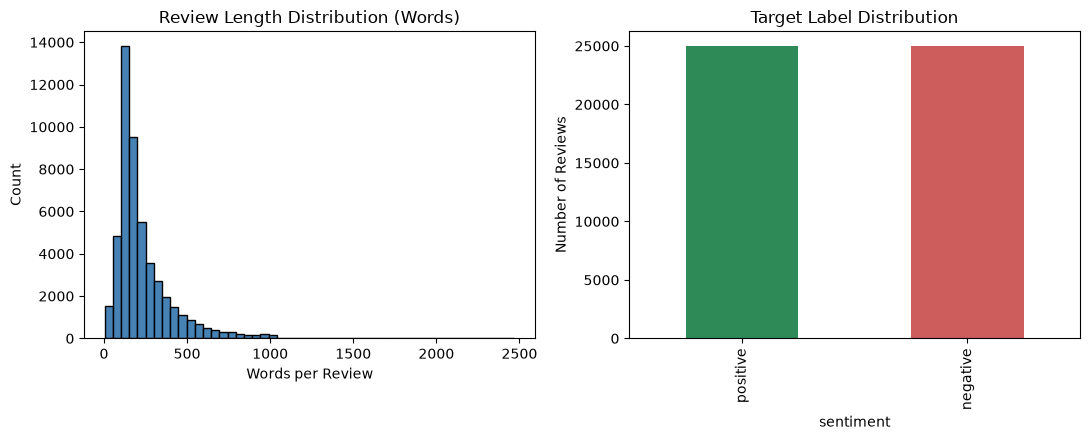

In [4]:
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].hist(word_counts, bins=50, color="steelblue", edgecolor="black")
axes[0].set_title("Review Length Distribution (Words)")
axes[0].set_xlabel("Words per Review")
axes[0].set_ylabel("Count")

df_raw["sentiment"].value_counts().plot(
    kind="bar", ax=axes[1], color=["seagreen", "indianred"]
)
axes[1].set_title("Target Label Distribution")
axes[1].set_ylabel("Number of Reviews")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "length_and_labels.png", dpi=150)
plt.show()

**Figure 1 — document lengths and class balance.**

The corpus is perfectly balanced (25,000 positive / 25,000 negative) and
skewed right in length: most reviews sit between 100 and 300 words, with a
long tail up to 2,470 words. Because the classes are balanced, accuracy is a
meaningful metric, but the length spread still matters — long reviews will
dominate any raw-count representation.

## 3. Vocabulary statistics (5,000-review sample)

Counting types over all 50,000 reviews would be slow and redundant, so we sample
5,000 reviews with `random_state=42` (reproducible). Tokens follow
`\w+|[^\w\s]` — words plus standalone punctuation — which mirrors the
tokenizer used later in `src/tokenization.py`.

In [5]:
SAMPLE_SIZE = 5000
sample_df = df_raw.sample(n=SAMPLE_SIZE, random_state=42)
token_pattern = re.compile(r"\w+|[^\w\s]")

all_tokens = []
for text in sample_df["review"]:
    all_tokens.extend(token_pattern.findall(text))

counts = Counter(all_tokens)
n_tokens = len(all_tokens)
n_types = len(counts)
ttr = n_types / n_tokens
hapax = sum(1 for freq in counts.values() if freq == 1)
top_100_share = sum(freq for _, freq in counts.most_common(100)) / n_tokens * 100

vocab = pd.DataFrame(
    {
        "Metric": [
            "Reviews sampled",
            "Tokens",
            "Types (unique tokens)",
            "Type-token ratio (TTR)",
            "Hapax legomena (seen once)",
            "Hapax share of types",
            "Share of tokens in top 100 types",
        ],
        "Value": [
            f"{len(sample_df):,}",
            f"{n_tokens:,}",
            f"{n_types:,}",
            f"{ttr:.3f}",
            f"{hapax:,}",
            f"{hapax / n_types * 100:.1f}%",
            f"{top_100_share:.1f}%",
        ],
    }
)
vocab

,Metric,Value
0,Reviews sampled,"5,000"
1,Tokens,"1,473,795"
2,Types (unique tokens),"47,046"
3,Type-token ratio (TTR),0.032
4,Hapax legomena (seen once),"19,951"
5,Hapax share of types,42.4%
6,Share of tokens in top 100 types,57.0%


In [6]:
top_tokens = pd.DataFrame(counts.most_common(10), columns=["Token", "Frequency"])
top_tokens

,Token,Frequency
0,.,65358
1,the,57986
2,",",55035
3,a,31364
4,and,31182
5,of,28900
6,',26805
7,to,26618
8,/,21512
9,is,21138


**Reading the numbers.** 1,473,795 tokens and 47,046 types give
TTR = **0.032**: the vocabulary is huge and flat, exactly what we expect from
free-form reviews. 19,951 types (42.4%) occur only once, and the 100 most
frequent types cover 57.0% of all tokens — so vocabulary pruning and
min-frequency thresholds are essential, and rare words carry little signal.

## 4. Zipf's law

Zipf's law predicts frequency ∝ 1/rank, i.e. a straight descending line on a
log-log plot. Raw IMDB text shows the classic shape: a steep head, a long
linear middle, and a sharp cliff at the tail where thousands of hapax legomena
sit at frequency 1.

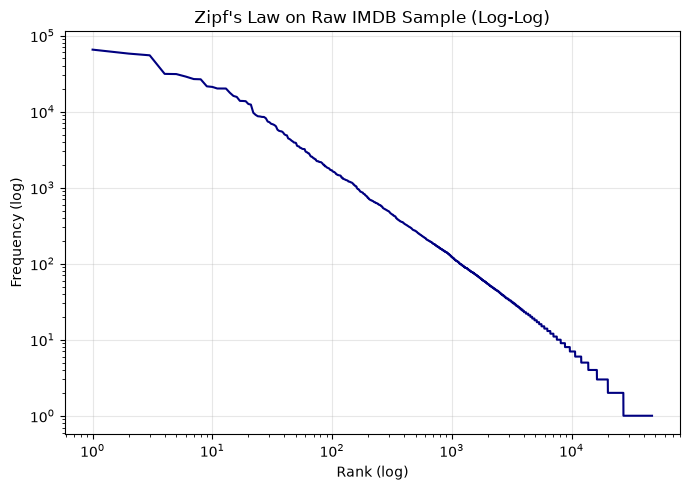

In [7]:
freqs = sorted(counts.values(), reverse=True)
ranks = np.arange(1, len(freqs) + 1)

plt.figure(figsize=(7, 5))
plt.loglog(ranks, freqs, color="navy")
plt.title("Zipf's Law on Raw IMDB Sample (Log-Log)")
plt.xlabel("Rank (log)")
plt.ylabel("Frequency (log)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "zipf_raw.png", dpi=150)
plt.show()

**Figure 2 — Zipf's law on the raw sample.** The plateau on the right is the
hapax cliff: roughly 42% of types were seen exactly once, so no frequency-based
model can learn them. Any tokenizer that keeps every rare token inflates the
feature space without adding signal.

## 5. How common is the mess?

Each pattern below is counted over all 50,000 raw reviews with a single regex
pass. These are the defects the cleaning stage must handle.

In [8]:
reviews = df_raw["review"]
mess_checks = {
    "HTML line breaks (<br />)": re.compile(r"<br\s*/?>", re.IGNORECASE),
    "ALL-CAPS words of 4+ letters": re.compile(r"\b[A-Z]{4,}\b"),
    "Explicit rating (8/10, 3 out of 10)": re.compile(
        r"\b\d+(?:\.\d+)?\s*(?:/\s*10|out of 10)\b", re.IGNORECASE
    ),
    "Non-ASCII characters": re.compile(r"[^\x00-\x7F]"),
    "Extra spaces or space before punct": re.compile(r"  +|\s+[,.!?]"),
    "Elongated words": re.compile(r"([A-Za-z])\1{2,}"),
    "URLs": re.compile(r"https?://|www\.", re.IGNORECASE),
}

rows = []
for name, pattern in mess_checks.items():
    count = int(reviews.apply(lambda text: pattern.search(text) is not None).sum())
    rows.append((name, count, count / len(df_raw) * 100))

mess_table = pd.DataFrame(rows, columns=["Pattern", "Reviews", "Share (%)"])
mess_table["Share (%)"] = mess_table["Share (%)"].round(1)
mess_table

,Pattern,Reviews,Share (%)
0,HTML line breaks (<br />),29200,58.4
1,ALL-CAPS words of 4+ letters,11339,22.7
2,"Explicit rating (8/10, 3 out of 10)",4381,8.8
3,Non-ASCII characters,4660,9.3
4,Extra spaces or space before punct,3196,6.4
5,Elongated words,1539,3.1
6,URLs,202,0.4


**Noise is not a corner case.** More than half of all reviews (58.4%) carry
`<br />` tags, 22.7% shout in ALL CAPS, and 9.3% contain non-ASCII characters —
so normalization, HTML stripping and case folding are mandatory, not optional
polish.

## 6. Real messy excerpts

Concrete examples pulled straight from the raw CSV, one per defect type, for
the report's data-quality section.

In [9]:
excerpt_patterns = {
    "HTML <br /> tags": r"<br\s*/?>",
    "Emphatic ALL-CAPS": r"\b[A-Z]{4,}\b",
    "Explicit rating like 9/10": r"\b9\s*/\s*10\b",
    "Elongated word (sooooo)": r"so{4,}",
}

for label, pattern in excerpt_patterns.items():
    rx = re.compile(pattern)
    hits = reviews.apply(rx.search)
    idx = int(np.flatnonzero(hits.notna().to_numpy())[0])
    match = hits.loc[idx]
    start = max(0, match.start() - 110)
    end = min(len(reviews.loc[idx]), match.end() + 150)
    snippet = " ".join(reviews.loc[idx][start:end].split())
    print(f"--- {label} (row {idx}) ---")
    print("... " + snippet + " ...\n")

--- HTML <br /> tags (row 0) ---
... t after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, thi ...

--- Emphatic ALL-CAPS (row 3) ---
... ike in real life. And then we have Jake with his closet which totally ruins all the film! I expected to see a BOOGEYMAN similar movie, and instead i watched a drama with some meaningless thriller spots.<br /><br />3 out of 10 just for the well playing parents & descent ...



--- Explicit rating like 9/10 (row 318) ---
... And don't forget to switch the light off.<br /><br />My points on different aspects:-<br /><br />Direction = 9/10 Acting = 8/10 Atmosphere = 10/10 Sound Effect = 9/10<br /><br />Total = 9/10 ...

--- Elongated word (sooooo) (row 1259) ---
... miserably short of being even somewhat effective(though entertaining for reasons it was not intending). It is sooooo preposterous. Apparently these ants that are bulldozed near an inn have been eating poisonous waste for decades and have now adapted by emitting pois ...



## 7. Summary of findings

| Finding | Value |
| --- | --- |
| Raw documents | 50,000 (418 exact duplicates) |
| Class balance | 25,000 positive / 25,000 negative (perfectly balanced) |
| Mean / median words | 231.2 / 173 (min 4, max 2,470) |
| Tokens in 5,000-review sample | 1,473,795 |
| Types / TTR | 47,046 / 0.032 |
| Hapax legomena | 19,951 (42.4% of types) |
| Reviews with `<br />` | 29,200 (58.4%) |
| Reviews with ALL-CAPS words | 11,339 (22.7%) |
| Reviews with explicit ratings | 4,381 (8.8%) |
| Reviews with non-ASCII characters | 4,660 (9.3%) |

**Implications for the pipeline.** Balanced labels mean accuracy is fair game.
The long-tailed, hapax-heavy vocabulary justifies lowercase folding,
lemmatization and min-frequency pruning. The high prevalence of HTML tags,
uppercase emphasis and ratings means cleaning must run before tokenization, and
the noise statistics in Section 5 give the before/after baseline for the
cleaning report.